# CSCI461 — Assignment #1: Dockerized Data, Text Analysis and Machine Learning
**Dataset:** YouTube Spam Collection (Option 3) — comments from 5 YouTube music videos (Psy, Katy Perry, LMFAO, Eminem, Shakira), each labeled spam (1) or ham/not-spam (0).

This notebook runs end-to-end (Kernel -> Restart & Run All) and writes all required artifacts under `output/`.

In [1]:
import pandas as pd
import numpy as np
import re
import string
import os
from collections import Counter

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                              f1_score, confusion_matrix, classification_report)
from sklearn.cluster import KMeans
from sklearn.decomposition import TruncatedSVD
from sklearn.metrics import silhouette_score
from sklearn.preprocessing import MinMaxScaler

sns.set_style("whitegrid")
plt.rcParams["figure.dpi"] = 100
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 140)

RANDOM_STATE = 42

# Jupyter sets the kernel's working directory to the folder that holds this
# .ipynb file (i.e. "notebook/"), not the project root. Move up one level so
# that "data/..." and "output/..." below always resolve to the project-root
# copies (and, inside the container, to the bind-mounted output/ folder) no
# matter where this notebook is launched from. The check keeps this safe to
# re-run (e.g. Restart & Run All) without chdir-ing up twice.
if os.path.basename(os.getcwd()) == "notebook":
    os.chdir("..")

OUTPUT_DIR = "output"
FIG_DIR = os.path.join(OUTPUT_DIR, "figures")
os.makedirs(FIG_DIR, exist_ok=True)

print("Working directory:", os.getcwd())
print("Setup complete.")

Working directory: /home/claude/bd-a1
Setup complete.


## 4.1 Dataset Understanding

Each **row** represents a single YouTube comment posted under one of five music videos, together with its author, posting date (where available), the comment text, and a spam/ham label.

- **Text column:** `CONTENT`
- **Label/category columns:** `CLASS` (0 = ham, 1 = spam), `VIDEO` (which of the 5 videos the comment was posted under)
- **Numerical columns:** `CLASS` (binary numeric label); the rest (`COMMENT_ID`, `AUTHOR`, `DATE`) are identifiers/metadata, not numeric features on their own.

In [2]:
df = pd.read_csv("data/dataset.csv")

print("Shape:", df.shape)
print("\nColumns:", list(df.columns))
print("\nDtypes:")
print(df.dtypes)
print("\nHead:")
print(df.head())
print("\ninfo():")
df.info()
print("\nDescriptive statistics (numeric):")
print(df.describe(include=[np.number]))
print("\nDescriptive statistics (object):")
print(df.describe(include=[object]))

Shape: (1956, 6)

Columns: ['COMMENT_ID', 'AUTHOR', 'DATE', 'CONTENT', 'CLASS', 'VIDEO']

Dtypes:
COMMENT_ID      str
AUTHOR          str
DATE            str
CONTENT         str
CLASS         int64
VIDEO           str
dtype: object

Head:
                                    COMMENT_ID            AUTHOR                 DATE                                            CONTENT  \
0  LZQPQhLyRh80UYxNuaDWhIGQYNQ96IuCg-AYWqNPjpU         Julius NM  2013-11-07T06:20:48  Huh, anyway check out this you[tube] channel: ...   
1  LZQPQhLyRh_C2cTtd9MvFRJedxydaVW-2sNg5Diuo4A       adam riyati  2013-11-07T12:37:15  Hey guys check out my new channel and our firs...   
2  LZQPQhLyRh9MSZYnf8djyk0gEF9BHDPYrrK-qCczIY8  Evgeny Murashkin  2013-11-08T17:34:21             just for test I have to say murdev.com   
3          z13jhp0bxqncu512g22wvzkasxmvvzjaz04   ElNino Melendez  2013-11-09T08:28:43   me shaking my sexy ass on my channel enjoy ^_^ ﻿   
4          z13fwbwp1oujthgqj04chlngpvzmtt3r3dw            GsM

## 4.2 Missing Values and Duplicates

In [3]:
print("Missing values per column:")
print(df.isnull().sum())

print("\nFully duplicate rows:", df.duplicated().sum())
print("Duplicate COMMENT_ID (same comment recorded twice):", df.duplicated(subset=["COMMENT_ID"]).sum())
print("Duplicate CONTENT (identical text, possibly different authors):", df.duplicated(subset=["CONTENT"]).sum())

shape_before = df.shape

# Drop true duplicate records (same COMMENT_ID appearing more than once = data entry duplication).
df = df.drop_duplicates(subset=["COMMENT_ID"]).reset_index(drop=True)

# DATE: convert to datetime; ~12% of rows have no date recorded in the source data.
# There is no reliable reference to impute a missing date from (comments are not stored in
# chronological order), so we leave these as NaT rather than fabricating a date, and avoid
# using DATE as a modeling feature later.
df["DATE"] = pd.to_datetime(df["DATE"], errors="coerce")

shape_after = df.shape
print("\nShape before cleaning:", shape_before)
print("Shape after cleaning:", shape_after)
print("Missing DATE after conversion:", df["DATE"].isnull().sum(), f"({df['DATE'].isnull().mean():.1%})")

Missing values per column:
COMMENT_ID      0
AUTHOR          0
DATE          245
CONTENT         0
CLASS           0
VIDEO           0
dtype: int64

Fully duplicate rows: 3
Duplicate COMMENT_ID (same comment recorded twice): 3
Duplicate CONTENT (identical text, possibly different authors): 196

Shape before cleaning: (1956, 6)
Shape after cleaning: (1953, 6)
Missing DATE after conversion: 1251 (64.1%)


**Decision & justification:** exact duplicate `COMMENT_ID` rows were dropped (true duplication). Rows with duplicate *text* but different author/comment IDs were **kept** — identical spam text posted by many different accounts is itself a meaningful spam signal, not a data error. Missing `DATE` values were left as missing (`NaT`) rather than imputed, since no reliable reference exists to infer them from.

## 4.3 `loc` / `iloc` Selection

In [4]:
# loc: conditional selection — long spam comments posted under the LMFAO video
long_spam_lmfao = df.loc[
    (df["CLASS"] == 1) & (df["CONTENT"].str.len() > 100) & (df["VIDEO"] == "LMFAO"),
    ["AUTHOR", "CONTENT", "CLASS"]
]
print("loc example — long spam comments under LMFAO:", long_spam_lmfao.shape)
print(long_spam_lmfao.head(3))

# iloc: positional selection — first 5 rows, first 3 columns
print("\niloc example — first 5 rows, first 3 columns:")
print(df.iloc[0:5, 0:3])

# iloc with np.r_: non-contiguous columns by position (COMMENT_ID, CONTENT, CLASS, VIDEO)
cols_idx = np.r_[0, 3, 4, 5]
print("\niloc + np.r_ example — non-contiguous columns:")
print(df.iloc[0:5, cols_idx])

loc example — long spam comments under LMFAO: (42, 3)
          AUTHOR                                            CONTENT  CLASS
702    LaS Music  Hey guys, I&#39;m a human.<br /><br /><br />Bu...      1
792  Terry Short  Support the fight for your 4th amendment right...      1
823   DrPunkable  okay, this should cover me for some time... Th...      1

iloc example — first 5 rows, first 3 columns:
                                    COMMENT_ID            AUTHOR                DATE
0  LZQPQhLyRh80UYxNuaDWhIGQYNQ96IuCg-AYWqNPjpU         Julius NM 2013-11-07 06:20:48
1  LZQPQhLyRh_C2cTtd9MvFRJedxydaVW-2sNg5Diuo4A       adam riyati 2013-11-07 12:37:15
2  LZQPQhLyRh9MSZYnf8djyk0gEF9BHDPYrrK-qCczIY8  Evgeny Murashkin 2013-11-08 17:34:21
3          z13jhp0bxqncu512g22wvzkasxmvvzjaz04   ElNino Melendez 2013-11-09 08:28:43
4          z13fwbwp1oujthgqj04chlngpvzmtt3r3dw            GsMega 2013-11-10 16:05:38

iloc + np.r_ example — non-contiguous columns:
                                    COMME

## 4.4 Transformation / Feature Creation

In [5]:
# 1) Type conversion: DATE -> datetime64 (done above)
print("1) Type conversion — DATE dtype:", df["DATE"].dtype)

# 2) Encoding: human-readable label + one-hot encode VIDEO (categorical -> numeric, model-ready)
df["CLASS_LABEL"] = df["CLASS"].map({0: "ham", 1: "spam"})
video_dummies = pd.get_dummies(df["VIDEO"], prefix="VIDEO")
df = pd.concat([df, video_dummies], axis=1)
print("\n2) Encoding — CLASS -> CLASS_LABEL mapping:")
print(df[["CLASS", "CLASS_LABEL"]].drop_duplicates().sort_values("CLASS"))
print("One-hot VIDEO columns created:", video_dummies.columns.tolist())

# 3) Feature creation + Binning: comment length, then bucket into short/medium/long
df["CONTENT_LENGTH"] = df["CONTENT"].str.len()
df["LENGTH_CATEGORY"] = pd.cut(
    df["CONTENT_LENGTH"],
    bins=[0, 40, 120, df["CONTENT_LENGTH"].max() + 1],
    labels=["short", "medium", "long"]
)
print("\n3) Feature creation + binning — LENGTH_CATEGORY distribution:")
print(df["LENGTH_CATEGORY"].value_counts())

# 4) Normalization: scale CONTENT_LENGTH to [0, 1]
scaler = MinMaxScaler()
df["CONTENT_LENGTH_NORM"] = scaler.fit_transform(df[["CONTENT_LENGTH"]])
print("\n4) Normalization — CONTENT_LENGTH vs CONTENT_LENGTH_NORM:")
print(df[["CONTENT_LENGTH", "CONTENT_LENGTH_NORM"]].describe())

1) Type conversion — DATE dtype: datetime64[us]

2) Encoding — CLASS -> CLASS_LABEL mapping:
   CLASS CLASS_LABEL
7      0         ham
0      1        spam
One-hot VIDEO columns created: ['VIDEO_Eminem', 'VIDEO_KatyPerry', 'VIDEO_LMFAO', 'VIDEO_Psy', 'VIDEO_Shakira']

3) Feature creation + binning — LENGTH_CATEGORY distribution:
LENGTH_CATEGORY
short     873
medium    694
long      386
Name: count, dtype: int64

4) Normalization — CONTENT_LENGTH vs CONTENT_LENGTH_NORM:
       CONTENT_LENGTH  CONTENT_LENGTH_NORM
count     1953.000000          1953.000000
mean        94.782386             0.077448
std        128.297958             0.107093
min          2.000000             0.000000
25%         29.000000             0.022538
50%         48.000000             0.038397
75%         97.000000             0.079299
max       1200.000000             1.000000


## 4.5 Sampling

In [6]:
SAMPLE_N = 300

# Simple random sampling
simple_sample = df.sample(n=SAMPLE_N, random_state=RANDOM_STATE)

# Stratified sampling (preserves CLASS proportions)
stratified_sample, _ = train_test_split(
    df, train_size=SAMPLE_N, stratify=df["CLASS"], random_state=RANDOM_STATE
)

# Cluster sampling — treat each VIDEO as a natural cluster; randomly select whole clusters
videos = df["VIDEO"].unique().tolist()
rng = np.random.RandomState(RANDOM_STATE)
chosen_videos = sorted(rng.choice(videos, size=3, replace=False).tolist())
cluster_sample = df[df["VIDEO"].isin(chosen_videos)]

print("Original CLASS distribution:")
print(df["CLASS"].value_counts(normalize=True).round(3))

print("\nSimple random sample CLASS distribution (n={}):".format(len(simple_sample)))
print(simple_sample["CLASS"].value_counts(normalize=True).round(3))

print("\nStratified sample CLASS distribution (n={}):".format(len(stratified_sample)))
print(stratified_sample["CLASS"].value_counts(normalize=True).round(3))

print(f"\nCluster sample — chosen clusters/videos: {chosen_videos}, n={len(cluster_sample)}")
print(cluster_sample["CLASS"].value_counts(normalize=True).round(3))

Original CLASS distribution:
CLASS
1    0.514
0    0.486
Name: proportion, dtype: float64

Simple random sample CLASS distribution (n=300):
CLASS
1    0.563
0    0.437
Name: proportion, dtype: float64

Stratified sample CLASS distribution (n=300):
CLASS
1    0.513
0    0.487
Name: proportion, dtype: float64

Cluster sample — chosen clusters/videos: ['KatyPerry', 'LMFAO', 'Shakira'], n=1157
CLASS
1    0.506
0    0.494
Name: proportion, dtype: float64


**Comparing the three methods:** simple random sampling draws individual rows uniformly, so its class balance can drift a little from the population just by chance. Stratified sampling deliberately preserves the spam/ham ratio because it samples proportionally *within* each class, so it tracks the population balance most closely. Cluster sampling selects whole natural groups (here, videos) rather than individual rows — its class balance depends entirely on which videos get picked, and can deviate the most since spam rates differ noticeably from one video to another.

## 4.6 Correlation

                   CHAR_COUNT  WORD_COUNT  UNIQUE_WORD_COUNT  AVG_WORD_LENGTH  CLASS
CHAR_COUNT              1.000       0.910              0.883            0.197  0.342
WORD_COUNT              0.910       1.000              0.973           -0.077  0.293
UNIQUE_WORD_COUNT       0.883       0.973              1.000           -0.086  0.297
AVG_WORD_LENGTH         0.197      -0.077             -0.086            1.000  0.099
CLASS                   0.342       0.293              0.297            0.099  1.000


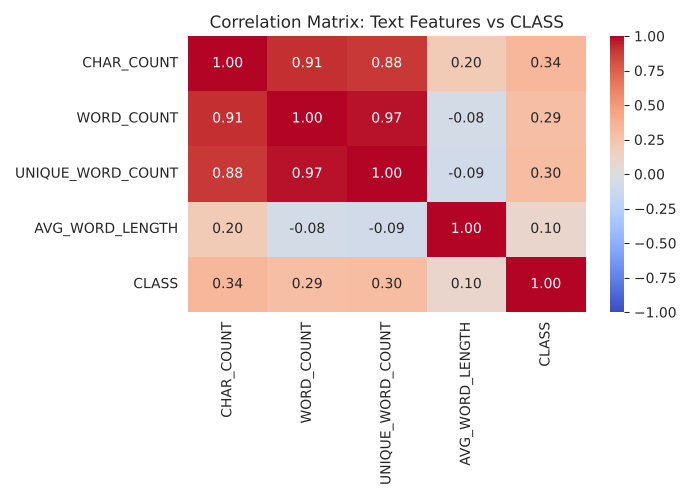

In [7]:
df["CHAR_COUNT"] = df["CONTENT"].str.len()
df["WORD_COUNT"] = df["CONTENT"].str.split().apply(len)
df["UNIQUE_WORD_COUNT"] = df["CONTENT"].str.split().apply(lambda ws: len(set(w.lower() for w in ws)))
df["AVG_WORD_LENGTH"] = df["CONTENT"].str.split().apply(
    lambda ws: np.mean([len(w) for w in ws]) if len(ws) > 0 else 0.0
)

corr_cols = ["CHAR_COUNT", "WORD_COUNT", "UNIQUE_WORD_COUNT", "AVG_WORD_LENGTH", "CLASS"]
corr_matrix = df[corr_cols].corr()
print(corr_matrix.round(3))

plt.figure(figsize=(7, 5))
sns.heatmap(corr_matrix, annot=True, cmap="coolwarm", fmt=".2f", vmin=-1, vmax=1)
plt.title("Correlation Matrix: Text Features vs CLASS")
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, "correlation_heatmap.png"))
plt.show()
plt.close()

**Interpretation:** `CHAR_COUNT` and `WORD_COUNT` are very strongly correlated (r≈0.91) — unsurprising, since both measure the same underlying property (comment length) in different units. `WORD_COUNT` and `UNIQUE_WORD_COUNT` are also very strongly correlated (r≈0.97): longer comments simply contain more distinct words. `CLASS` has only a **moderate** correlation with length (`CHAR_COUNT` r≈0.34, `WORD_COUNT` r≈0.29) — spam comments do tend to run longer, but length alone is far from a perfect spam signal. `AVG_WORD_LENGTH` is weakly related to everything (r≈0.10 with `CLASS`). **Correlation here does not imply causation:** longer comments are not spam *because* they are long — spam comments tend to be longer because the underlying intent (promote a channel/link, with a greeting and a call-to-action) naturally takes more words than a short genuine reaction like "love this song!". The real driver is comment *intent*, which happens to produce both the label and the length.

## 5. Text Analysis

In [8]:
def clean_text(text):
    text = str(text)
    text = text.lower()
    text = re.sub(r"http\S+|www\.\S+", " ", text)       # URLs
    text = re.sub(r"&\w+;", " ", text)                   # HTML entities (&quot; etc.)
    text = text.replace("\ufeff", " ")                   # stray BOM/zero-width char
    text = re.sub(r"\d+", " ", text)                     # numbers
    text = re.sub(f"[{re.escape(string.punctuation)}]", " ", text)  # punctuation
    text = re.sub(r"\s+", " ", text).strip()              # extra whitespace
    return text

df["CONTENT"] = df["CONTENT"].fillna("")
df["cleaned_text"] = df["CONTENT"].apply(clean_text)

print("Original vs cleaned_text (sample):")
print(df[["CONTENT", "cleaned_text"]].sample(5, random_state=1).to_string())

Original vs cleaned_text (sample):
                                                                             CONTENT                                                        cleaned_text
983                                                                       subscribe﻿                                                           subscribe
534   If only I had the body like Katy Perry :)). She looks so hot. I love her  ^^!﻿  if only i had the body like katy perry she looks so hot i love her
1621                                                                 Love this song﻿                                                      love this song
1010                                               Check out this video on YouTube:﻿                                     check out this video on youtube
1726                                              THIS IS SHIT AND SOOOOO AUTOTUNED﻿                                   this is shit and sooooo autotuned


In [9]:
df["tokens"] = df["cleaned_text"].str.split()
all_tokens = [t for toks in df["tokens"] for t in toks]
total_tokens = len(all_tokens)
unique_words = len(set(all_tokens))
avg_words_per_record = df["tokens"].apply(len).mean()

print(f"Total tokens: {total_tokens}")
print(f"Unique words: {unique_words}")
print(f"Average words per record: {avg_words_per_record:.2f}")

Total tokens: 30119
Unique words: 3808
Average words per record: 15.42


Top 20 words (before stopword removal):
      word  count
0        i    906
1     this    737
2      the    716
3      and    640
4       to    634
5      you    610
6      out    584
7       my    580
8        a    571
9    check    570
10      on    389
11      it    379
12      is    331
13   video    311
14      of    310
15    song    288
16     for    264
17      br    257
18      me    250
19  please    249


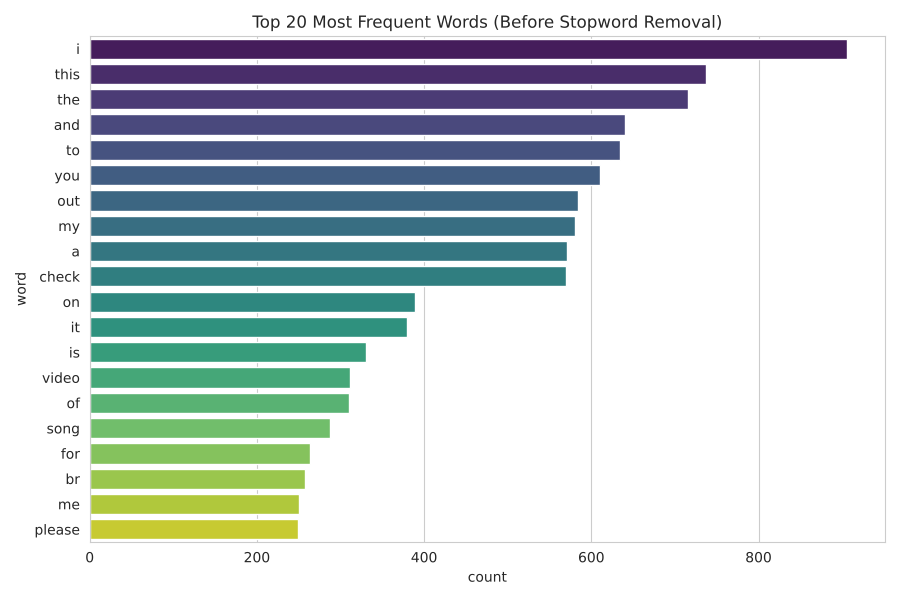

In [10]:
word_freq = Counter(all_tokens)
top20_df = pd.DataFrame(word_freq.most_common(20), columns=["word", "count"])
print("Top 20 words (before stopword removal):")
print(top20_df)

plt.figure(figsize=(9, 6))
sns.barplot(data=top20_df, y="word", x="count", hue="word", palette="viridis", legend=False)
plt.title("Top 20 Most Frequent Words (Before Stopword Removal)")
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, "top20_words_raw.png"))
plt.show()
plt.close()

Top 20 words (after stopword removal):
         word  count
0       check    570
1       video    311
2        song    288
3          br    257
4      please    249
5        like    249
6     youtube    247
7   subscribe    228
8     channel    198
9        love    195
10        can    160
11      music    156
12        new    122
13       guys    119
14        com    115
15       will    112
16      views    110
17        get     99
18      money     91
19       make     89

Stopwords present in the raw top-20 list: ['a', 'and', 'for', 'i', 'is', 'it', 'me', 'my', 'of', 'on', 'out', 'the', 'this', 'to', 'you'] (15 of 20)


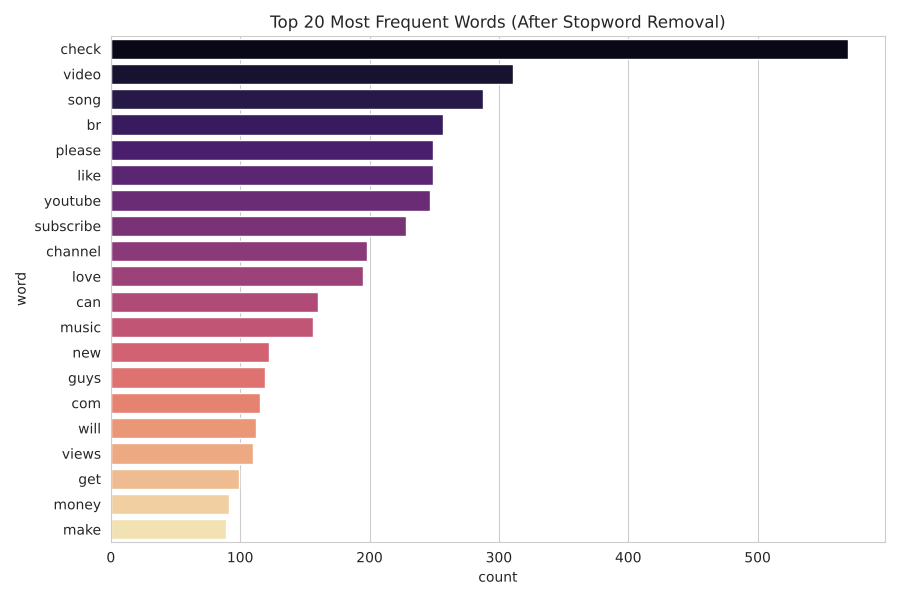

In [11]:
STOPWORDS = set("""a about above after again against all am an and any are aren't as at be because been before
being below between both but by can't cannot could couldn't did didn't do does doesn't doing don't down during
each few for from further had hadn't has hasn't have haven't having he he'd he'll he's her here here's hers
herself him himself his how how's i i'd i'll i'm i've if in into is isn't it it's its itself just let's me more
most mustn't my myself no nor not of off on once only or other ought our ours ourselves out over own same shan't
she she'd she'll she's should shouldn't so some such than that that's the their theirs them themselves then
there there's these they they'd they'll they're they've this those through to too under until up very was wasn't
we we'd we'll we're we've were weren't what what's when when's where where's which while who who's whom why
why's with won't would wouldn't you you'd you'll you're you've your yours yourself yourselves""".split())

df["tokens_nostop"] = df["tokens"].apply(lambda toks: [t for t in toks if t not in STOPWORDS and len(t) > 1])
all_tokens_nostop = [t for toks in df["tokens_nostop"] for t in toks]
word_freq_nostop = Counter(all_tokens_nostop)
top20_nostop_df = pd.DataFrame(word_freq_nostop.most_common(20), columns=["word", "count"])

print("Top 20 words (after stopword removal):")
print(top20_nostop_df)

overlap = set(top20_df["word"]) & STOPWORDS
print(f"\nStopwords present in the raw top-20 list: {sorted(overlap)} ({len(overlap)} of 20)")

plt.figure(figsize=(9, 6))
sns.barplot(data=top20_nostop_df, y="word", x="count", hue="word", palette="magma", legend=False)
plt.title("Top 20 Most Frequent Words (After Stopword Removal)")
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, "top20_words_nostop.png"))
plt.show()
plt.close()

**Stopwords dominate the raw list:** 15 of the raw top-20 words ("my", "is", "out", "of", "on", "a", "it", "this", "the", "me", "i", "to", "you", "for", "and") are stopwords with little topical meaning. After removing them, the top words become genuinely informative — content words like "song", "love", "check", "subscribe", "channel" surface instead, confirming stopword removal is a necessary step before frequency analysis is useful.

Group comparison — spam vs ham:
             avg_char_length  avg_word_count     n
CLASS_LABEL                                       
ham                    49.69            9.11   950
spam                  137.50           21.73  1003

Top 10 words — ham:
[('song', 222), ('love', 143), ('like', 90), ('views', 87), ('video', 84), ('br', 64), ('billion', 56), ('best', 56), ('katy', 56), ('good', 48)]

Top 10 words — spam:
[('check', 557), ('please', 246), ('subscribe', 227), ('video', 227), ('youtube', 225), ('channel', 197), ('br', 193), ('like', 159), ('can', 137), ('new', 119)]


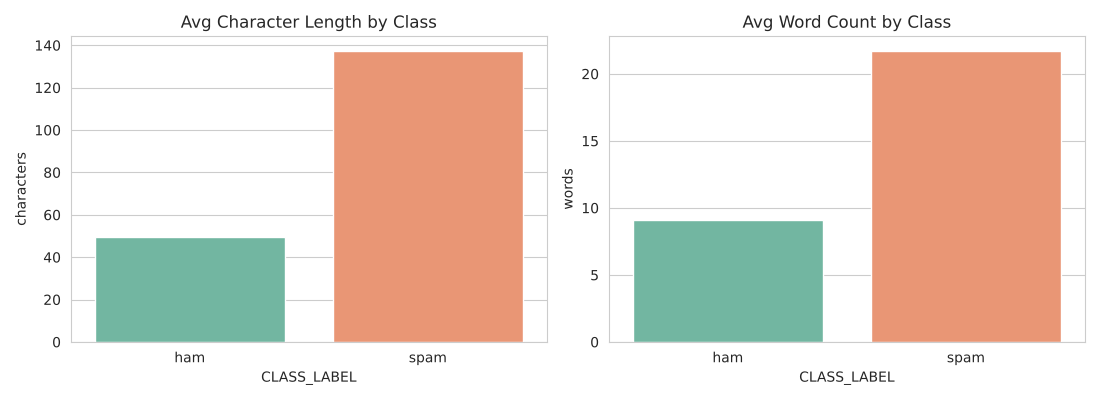

In [12]:
group_stats = df.groupby("CLASS_LABEL").agg(
    avg_char_length=("CHAR_COUNT", "mean"),
    avg_word_count=("WORD_COUNT", "mean"),
    n=("CLASS_LABEL", "count"),
)
print("Group comparison — spam vs ham:")
print(group_stats.round(2))

top10_by_class = {}
for label in ["ham", "spam"]:
    toks = [t for toks in df.loc[df["CLASS_LABEL"] == label, "tokens_nostop"] for t in toks]
    top10 = Counter(toks).most_common(10)
    top10_by_class[label] = top10
    print(f"\nTop 10 words — {label}:")
    print(top10)

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
sns.barplot(x=group_stats.index, y=group_stats["avg_char_length"], hue=group_stats.index,
            ax=axes[0], palette="Set2", legend=False)
axes[0].set_title("Avg Character Length by Class")
axes[0].set_ylabel("characters")
sns.barplot(x=group_stats.index, y=group_stats["avg_word_count"], hue=group_stats.index,
            ax=axes[1], palette="Set2", legend=False)
axes[1].set_title("Avg Word Count by Class")
axes[1].set_ylabel("words")
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, "group_comparison_spam_ham.png"))
plt.show()
plt.close()

### Insights

**1. Spam comments are far longer than ham comments.**
Observation: spam averages 137.5 characters / 21.7 words per comment vs. ham's 49.7 characters / 9.1 words.
Evidence: `group_stats` table above.
Interpretation: spam needs room for a greeting, a call-to-action and a link/channel plug, while genuine reactions are typically short ("love this song!").

**2. Spam and ham vocabularies reflect different intents.**
Observation: spam's top words are check, please, subscribe, video, youtube, channel; ham's top words are song, love, like, views, video, billion, best.
Evidence: per-class top-10 word lists above.
Interpretation: spammers reuse a recognizable promotional template, while genuine viewers talk about the song/video itself.

**3. Raw word frequency is dominated by stopwords, masking real content signal.**
Observation: 15 of the raw top-20 words are stopwords.
Evidence: the stopword-overlap check above.
Interpretation: removing stopwords is a necessary preprocessing step before word-frequency analysis is meaningful — directly confirmed, not just assumed.

**4. Length correlates with spam only moderately, and length features are redundant with each other.**
Observation: CHAR_COUNT vs CLASS r≈0.34, WORD_COUNT vs CLASS r≈0.29 (moderate); CHAR_COUNT vs WORD_COUNT r≈0.91 (very strong — same information).
Evidence: correlation matrix above.
Interpretation: length alone is a useful but weak-to-moderate spam signal, which is why the classifier below relies on full TF-IDF word content rather than length alone.

**5. Leftover HTML artifacts surfaced as a real data-quality finding.**
Observation: the token "br" appears among the top words for *both* classes (64 times in ham, 193 in spam) and among a K-Means cluster's top terms.
Evidence: per-class top-10 lists and cluster top-terms (Section 6.2).
Interpretation: the original CONTENT field contains leftover `<br>` line-break tags; stripping punctuation removed the angle brackets but left the letters "br" behind as a spurious word — a genuine artifact the pipeline surfaced, and a candidate for a stricter cleaning step (explicit HTML-tag removal) in a future iteration.

## 6.1 Supervised Text Classification

Train size: 1562  |  Test size: 391

Accuracy:  0.8875
Precision: 0.8552
Recall:    0.9403
F1-score:  0.8957

Confusion matrix (rows=actual, cols=predicted) [ham, spam]:
[[158  32]
 [ 12 189]]

               precision    recall  f1-score   support

         ham       0.93      0.83      0.88       190
        spam       0.86      0.94      0.90       201

    accuracy                           0.89       391
   macro avg       0.89      0.89      0.89       391
weighted avg       0.89      0.89      0.89       391


Saved output/model_metrics.txt


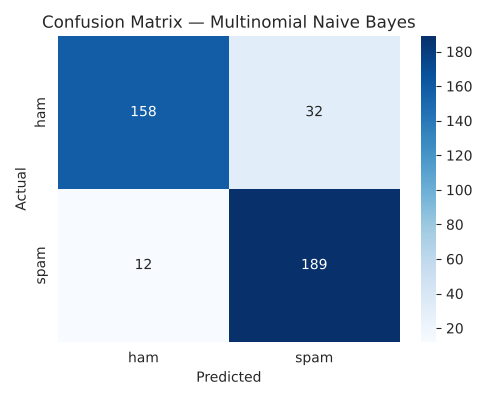

In [13]:
X = df["cleaned_text"]
y = df["CLASS"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE
)

tfidf = TfidfVectorizer(max_features=3000, ngram_range=(1, 1))
X_train_tfidf = tfidf.fit_transform(X_train)
X_test_tfidf = tfidf.transform(X_test)

nb = MultinomialNB()
nb.fit(X_train_tfidf, y_train)
y_pred = nb.predict(X_test_tfidf)

acc = accuracy_score(y_test, y_pred)
prec = precision_score(y_test, y_pred)
rec = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)
cm = confusion_matrix(y_test, y_pred)

print(f"Train size: {X_train.shape[0]}  |  Test size: {X_test.shape[0]}")
print(f"\nAccuracy:  {acc:.4f}")
print(f"Precision: {prec:.4f}")
print(f"Recall:    {rec:.4f}")
print(f"F1-score:  {f1:.4f}")
print("\nConfusion matrix (rows=actual, cols=predicted) [ham, spam]:")
print(cm)
print("\n", classification_report(y_test, y_pred, target_names=["ham", "spam"]))

plt.figure(figsize=(5, 4))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=["ham", "spam"], yticklabels=["ham", "spam"])
plt.xlabel("Predicted"); plt.ylabel("Actual")
plt.title("Confusion Matrix — Multinomial Naive Bayes")
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, "confusion_matrix.png"))
plt.show()
plt.close()

with open(os.path.join(OUTPUT_DIR, "model_metrics.txt"), "w") as f:
    f.write("Supervised Text Classification - Multinomial Naive Bayes (TF-IDF features)\n")
    f.write("=" * 72 + "\n")
    f.write(f"Train size: {X_train.shape[0]}, Test size: {X_test.shape[0]}\n\n")
    f.write(f"Accuracy:  {acc:.4f}\n")
    f.write(f"Precision: {prec:.4f}\n")
    f.write(f"Recall:    {rec:.4f}\n")
    f.write(f"F1-score:  {f1:.4f}\n\n")
    f.write("Confusion Matrix (rows=actual, cols=predicted) [ham, spam]:\n")
    f.write(str(cm) + "\n\n")
    f.write(classification_report(y_test, y_pred, target_names=["ham", "spam"]))

print("\nSaved output/model_metrics.txt")

**Interpretation:** the model reaches ~88.7% accuracy, with spam **recall of ~94%** — it catches the large majority of actual spam, which matters most in a spam filter. **Precision is lower, ~85.5%**: of the comments flagged as spam, about 1 in 7 was actually ham (32 false positives out of 190 true ham), likely genuine enthusiastic comments ("check out this amazing video!!") that share vocabulary with the spam template.

**Limitation:** the model is trained and tested on only ~2,000 comments from five specific, older pop-music videos, so its learned vocabulary is narrow; it may not generalize well to spam on unrelated video genres, other languages, or newer spam phrasing it has never seen. Unigram TF-IDF + Naive Bayes also ignores word order and context, so a spam message that avoids typical trigger words like "subscribe" or "channel" could slip through undetected.

## 6.2 K-Means Clustering

In [14]:
tfidf_full = TfidfVectorizer(max_features=3000)
X_tfidf_full = tfidf_full.fit_transform(df["cleaned_text"])

svd = TruncatedSVD(n_components=50, random_state=RANDOM_STATE)
X_reduced = svd.fit_transform(X_tfidf_full)

sil_scores = {}
for k in range(2, 7):
    km = KMeans(n_clusters=k, random_state=RANDOM_STATE, n_init=10)
    labels = km.fit_predict(X_reduced)
    sil_scores[k] = silhouette_score(X_reduced, labels)
    print(f"k={k}: silhouette={sil_scores[k]:.4f}")

best_k = max(sil_scores, key=sil_scores.get)
print(f"\nChosen k = {best_k} (highest silhouette score among k=2..6)")

kmeans = KMeans(n_clusters=best_k, random_state=RANDOM_STATE, n_init=10)
df["cluster"] = kmeans.fit_predict(X_reduced)
final_sil = silhouette_score(X_reduced, df["cluster"])

cluster_sizes = df["cluster"].value_counts().sort_index()
print("\nCluster sizes:")
print(cluster_sizes)
print(f"\nFinal silhouette score (k={best_k}): {final_sil:.4f}")

feature_names = np.array(tfidf_full.get_feature_names_out())
cluster_top_terms = {}
for c in sorted(df["cluster"].unique()):
    idx = (df["cluster"] == c).values
    mean_tfidf = np.asarray(X_tfidf_full[idx].mean(axis=0)).flatten()
    top_idx = mean_tfidf.argsort()[::-1][:10]
    cluster_top_terms[c] = feature_names[top_idx].tolist()
    print(f"\nCluster {c} (n={idx.sum()}) top terms:", cluster_top_terms[c])

crosstab = pd.crosstab(df["cluster"], df["CLASS_LABEL"])
print("\nCluster vs known CLASS label (crosstab):")
print(crosstab)

with open(os.path.join(OUTPUT_DIR, "cluster_summary.txt"), "w") as f:
    f.write("K-Means Clustering on TF-IDF (SVD-reduced) Text Features\n")
    f.write("=" * 60 + "\n")
    f.write(f"Chosen k = {best_k} (best silhouette among k=2..6)\n\n")
    f.write("Silhouette scores by k:\n")
    for k, s in sil_scores.items():
        f.write(f"  k={k}: {s:.4f}\n")
    f.write(f"\nFinal silhouette score: {final_sil:.4f}\n\n")
    f.write("Cluster sizes:\n")
    f.write(str(cluster_sizes) + "\n\n")
    f.write("Cluster vs known CLASS label (crosstab):\n")
    f.write(str(crosstab) + "\n\n")
    f.write("Top terms per cluster:\n")
    for c, terms in cluster_top_terms.items():
        f.write(f"  Cluster {c} (n={(df['cluster']==c).sum()}): {terms}\n")

print("\nSaved output/cluster_summary.txt")

k=2: silhouette=0.3226
k=3: silhouette=0.2531
k=4: silhouette=0.1339
k=5: silhouette=0.1463
k=6: silhouette=0.1336

Chosen k = 2 (highest silhouette score among k=2..6)

Cluster sizes:
cluster
0     151
1    1802
Name: count, dtype: int64

Final silhouette score (k=2): 0.3226

Cluster 0 (n=151) top terms: ['youtube', 'on', 'out', 'check', 'video', 'this', 'playlist', 'br', 'youtu', 'jjiwajwkajajqjaubkm']

Cluster 1 (n=1802) top terms: ['my', 'the', 'song', 'this', 'love', 'to', 'you', 'and', 'subscribe', 'is']

Cluster vs known CLASS label (crosstab):
CLASS_LABEL  ham  spam
cluster               
0              0   151
1            950   852

Saved output/cluster_summary.txt


**Why K-Means is unsupervised:** it only ever sees the TF-IDF/SVD text vectors and groups rows by distance to the nearest centroid — the `CLASS` label is never shown to `.fit_predict()`, unlike the supervised classifier above which explicitly learns from labeled examples.

**Choosing k:** silhouette score was highest at k=2 (0.323) and dropped steadily for k=3–6, so k=2 was selected rather than forcing k=3.

**Cluster interpretation:** Cluster 0 (n=151) is almost purely spam (0 ham, 151 spam) with top terms "youtube", "check", "video", "playlist", "youtu" — a fairly homogeneous link-sharing promo template. Cluster 1 (n=1,802) is much larger and mixed (950 ham + 852 spam), with top terms like "song", "love", "subscribe" — it absorbs essentially all of the ham plus the spam comments that are phrased more like natural sentences rather than a repeated template.

**Clusters vs. known labels:** as expected, cluster IDs do **not** line up 1:1 with the spam/ham labels — K-Means found one tight, recognizable spam sub-pattern, but most spam is textually too similar to ordinary comments (or too varied in phrasing) to separate from ham using unsupervised similarity alone.

## 7. Save Final Cleaned Dataset

In [15]:
final_cols = [
    "COMMENT_ID", "AUTHOR", "DATE", "VIDEO", "CONTENT", "cleaned_text",
    "CLASS", "CLASS_LABEL", "CHAR_COUNT", "WORD_COUNT", "UNIQUE_WORD_COUNT",
    "AVG_WORD_LENGTH", "LENGTH_CATEGORY", "cluster"
]
df[final_cols].to_csv(os.path.join(OUTPUT_DIR, "cleaned_data.csv"), index=False)
print("Saved output/cleaned_data.csv with shape:", df[final_cols].shape)

Saved output/cleaned_data.csv with shape: (1953, 14)
